In [5]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
if root.name == "notebook":
    root = root.parent

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

In [6]:
import pandas as pd
data = pd.read_parquet('../data/clustered/customer_scaled.parquet')

,Algorithm,Clusters (k),Noise (%),Silhouette,Davies-Bouldin,Calinski-Harabasz,Min Cluster Size (%),Max Cluster Size (%)
0,K-Means,4,0.00,0.2403,1.2992,1376.3,16.44,35.97
1,Hierarchical,4,0.00,0.1729,1.4833,1090.2,17.25,33.15
2,GMM,4,0.00,0.0740,2.7201,661.5,16.69,34.28
3,DBSCAN,1,3.33,NaN,NaN,NaN,96.67,96.67


(<Figure size 1400x1100 with 4 Axes>,
 array([<Axes: title={'center': 'K-Means Clusters (2D PCA Projection)'}, xlabel='PC1 (44.7% Variance)', ylabel='PC2 (20.2% Variance)'>,
        <Axes: title={'center': 'GMM Clusters (2D PCA Projection)'}, xlabel='PC1 (44.7% Variance)', ylabel='PC2 (20.2% Variance)'>,
        <Axes: title={'center': 'Hierarchical Clusters (2D PCA Projection)'}, xlabel='PC1 (44.7% Variance)', ylabel='PC2 (20.2% Variance)'>,
        <Axes: title={'center': 'DBSCAN Clusters (2D PCA Projection)'}, xlabel='PC1 (44.7% Variance)', ylabel='PC2 (20.2% Variance)'>],
       dtype=object))

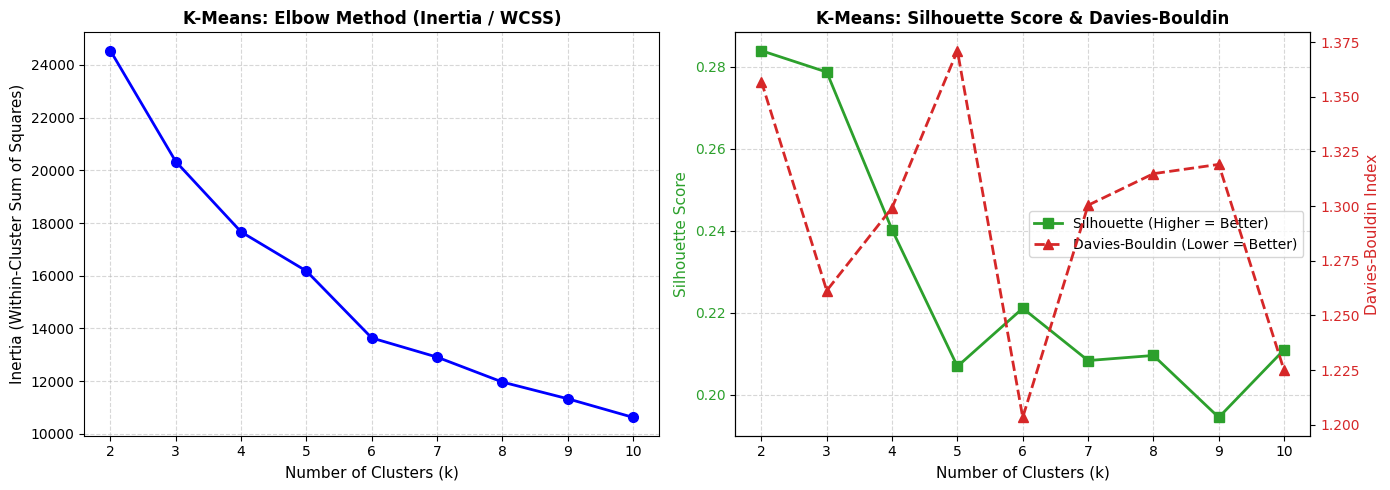

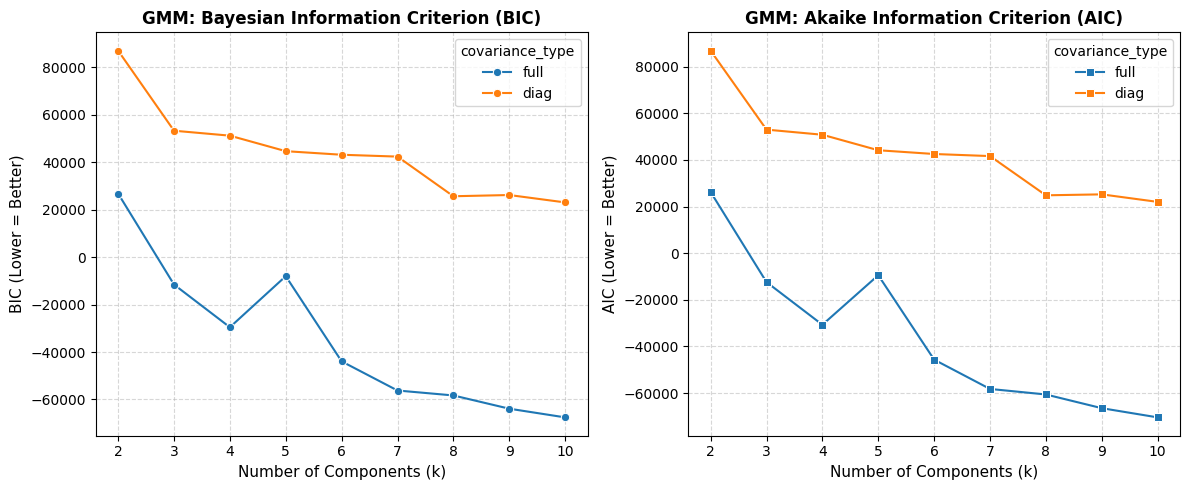

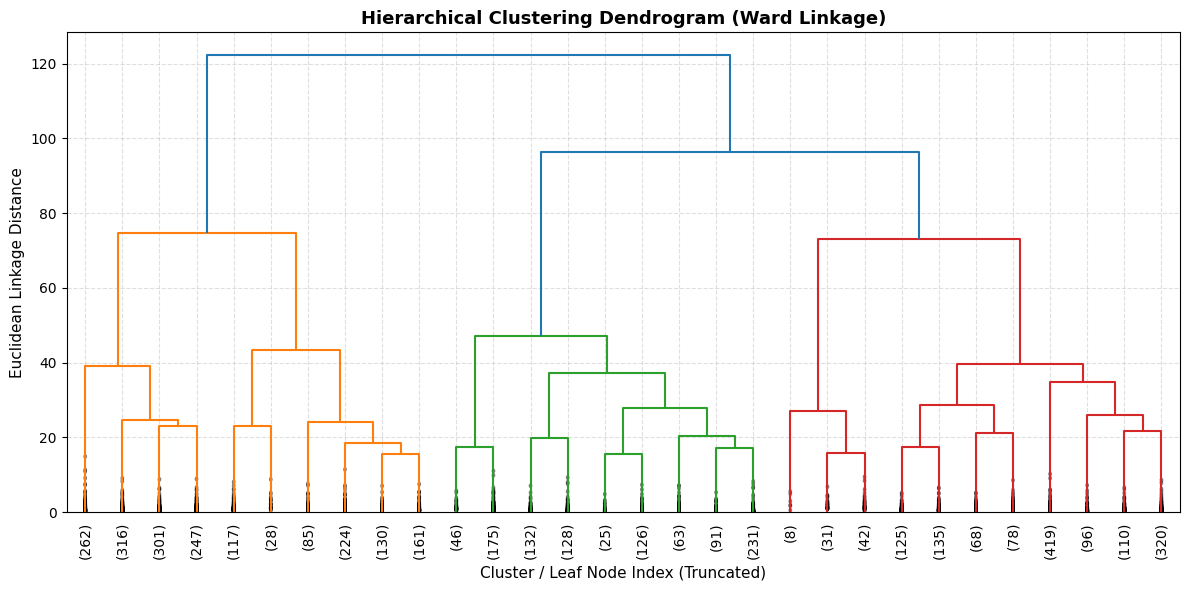

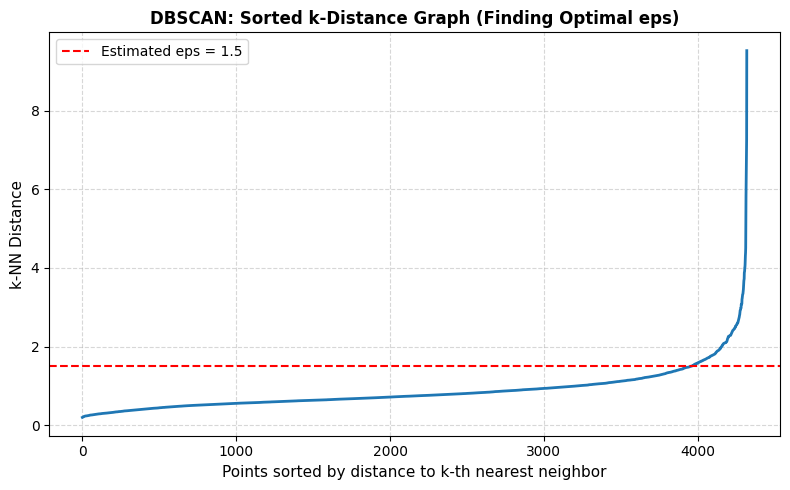

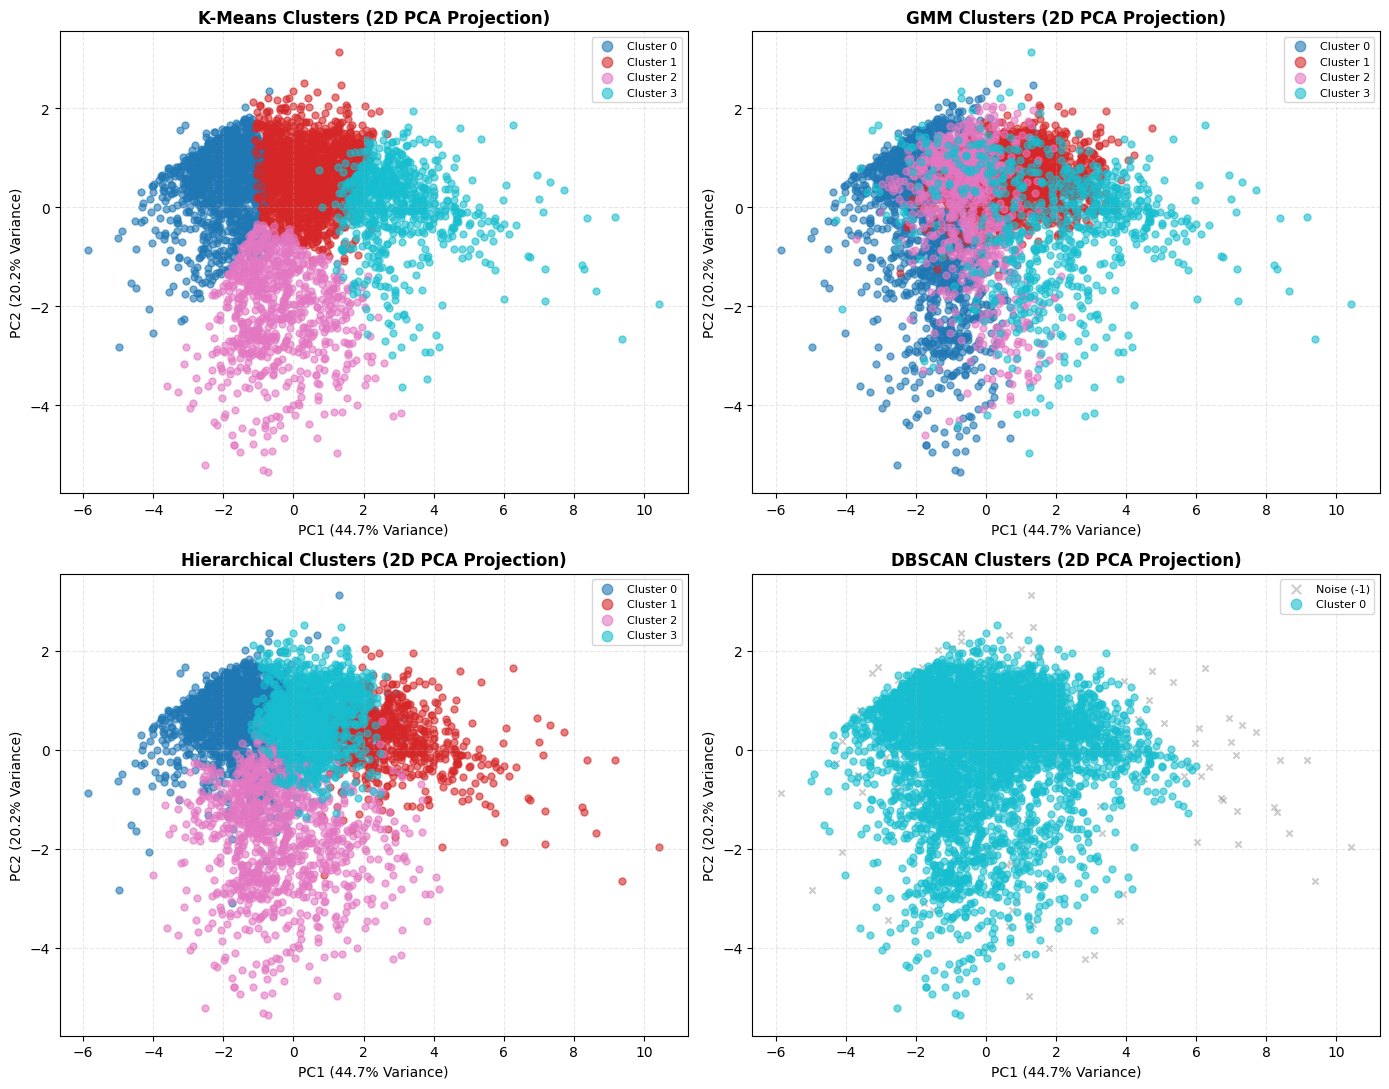

In [7]:
from src.clustering import (
    # algorithm
    run_kmeans, run_dbscan, run_gmm, run_hierarchical,
    # evaluation
    evaluate_hierarchical_range, evaluate_dbscan_grid, evaluate_gmm_range,
    evaluate_kmeans_range, find_k_distance_elbow, compare_clustering_algorithms,
    # visiualizing
    plot_kmeans_metrics, plot_gmm_aic_bic, plot_hierarchical_dendrogram,
    plot_k_distance_graph, plot_cluster_projections
)

X = data.drop(columns=['CustomerID']).values

# Find optimal K for KMeans
km_metrics = evaluate_kmeans_range(X, k_range=range(2,11))
plot_kmeans_metrics(km_metrics)

# Find optimal component for GMM based on BIC, AIC
gmm_metrics = evaluate_gmm_range(X, k_range=range(2,11))
covariance_types=("full", "diag")
plot_gmm_aic_bic(gmm_metrics)

# Dendogram for HCA
plot_hierarchical_dendrogram(X, linkage_method='ward', p=30)

# Eps for DBSCAN through k-distance graph
k_dist = find_k_distance_elbow(X)
plot_k_distance_graph(k_dist, knee_point=1.5)

# Running 4 algorithms with chosen paramenter
_, km_lbl = run_kmeans(X, n_clusters=4)
_, gmm_lbl = run_gmm(X, n_components=4)
_, h_lbl = run_hierarchical(X, n_clusters=4)
_, db_lbl = run_dbscan(X, eps=1.5, min_samples=10)


models_to_compare = {
    'K-Means': km_lbl,
    'GMM': gmm_lbl,
    'Hierarchical': h_lbl,
    'DBSCAN': db_lbl
}

comparison_table = compare_clustering_algorithms(X, models_to_compare)
display(comparison_table)

plot_cluster_projections(X, models_to_compare)

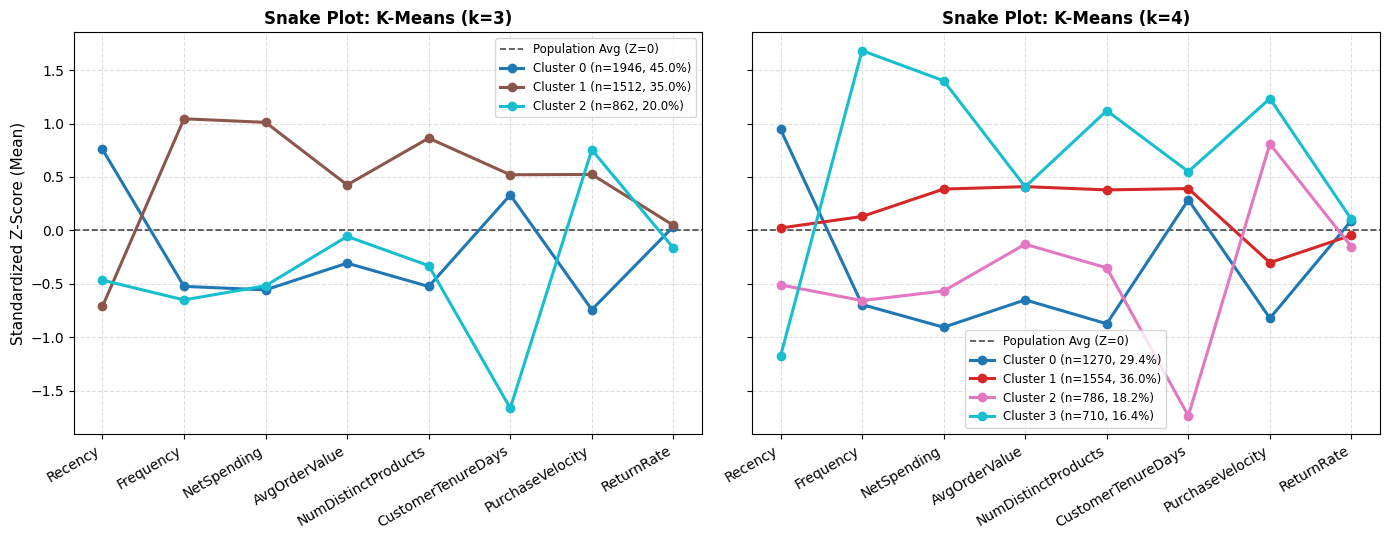

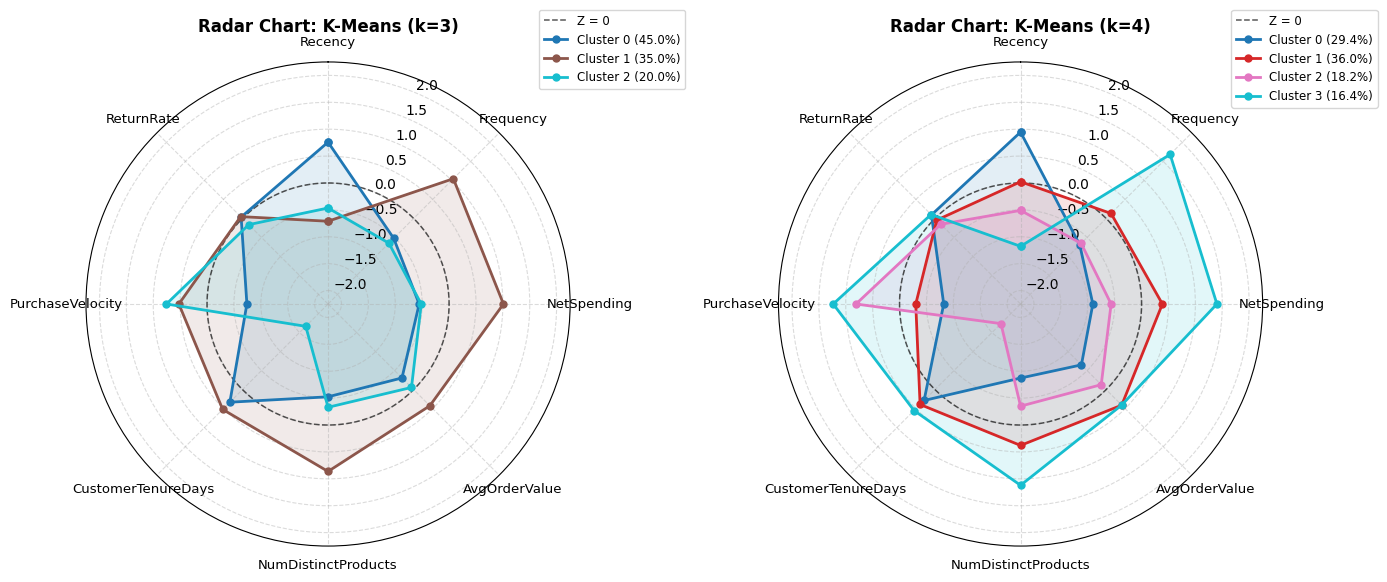

In [10]:
from src.clustering import (
    run_kmeans,
    plot_snake_comparison,
    plot_radar_comparison,
)
import matplotlib.pyplot as plt

# Run K-Means with k = 3 and k = 4
_, labels_k3 = run_kmeans(X, n_clusters=3, random_state=42)
_, labels_k4 = run_kmeans(X, n_clusters=4, random_state=42)

comparison_labels = {
    'K-Means (k=3)': labels_k3,
    'K-Means (k=4)': labels_k4,
}

# Snake Plot
fig_snake, _ = plot_snake_comparison(data, comparison_labels, agg='mean')
plt.show()

# Radar Chart
fig_radar, _ = plot_radar_comparison(data, comparison_labels, agg='mean')
plt.show()

#### Comprehensive Clustering Summary: Insights, Model Selection, and Strategic Actions

**1. K-Means Evaluation Across K = 2 to 10 (Inertia, Silhouette, Davies-Bouldin, Calinski-Harabasz)**
- Insight: As `K` increases from `2` to `10`, Inertia and Calinski-Harabasz decline smoothly without a sharp geometric elbow, confirming that customer purchasing behaviors form a continuous spectrum rather than disconnected islands. Silhouette peaks at `K = 2` (`0.335`, a trivial active-vs-inactive binary split) and stabilizes across `K = 3` (`0.258`) and `K = 4` (`0.240`) before dropping to `0.221` at `K = 5`. Crucially, the Davies-Bouldin Index (lower is better) improves when moving from `K = 3` (`1.351`) to a local minimum at `K = 4` (`1.299`), indicating that 4 clusters achieve higher compactness and lower inter-cluster similarity than 3 clusters.
- Action: Narrow the candidate cluster count for K-Means to `K = 3` and `K = 4` for deeper behavioral profiling via Snake Plot and Radar Chart.

**2. Gaussian Mixture Model (GMM) AIC and BIC Evaluation (`full` vs. `diag` Covariance)**
- Insight: Both AIC and BIC decrease monotonically through `K = 10`, with `full` covariance consistently achieving lower values than `diag` covariance (`BIC ~ 21,000` vs. `~ 59,000` at `K = 4`). However, this statistical drop is driven by the zero-inflated nature of `ReturnRate_scaled` (`63.6%` of customers have zero returns, creating a dense hyperplane at `ReturnRate = 0`) and non-Gaussian tails in `Frequency_scaled`. GMM fits extra stretched Gaussian components to approximate non-normal density rather than discovering meaningful business segments.
- Action: Do not rely on the minimum BIC (`K = 9-10`) to select cluster count; evaluate GMM at `K = 4` alongside K-Means and Hierarchical Clustering.

**3. Hierarchical Clustering Ward Dendrogram**
- Insight: The Ward linkage dendrogram exhibits two dominant vertical merge jumps: the primary split at Euclidean distance `~86` (`K = 2`) and a secondary major split between distances `~35` and `~53` (`K = 3` to `K = 4`). Below distance `25` (`K >= 5`), merge heights compress tightly, signaling over-segmentation of homogeneous customer groups.
- Action: Cut the Ward dendrogram at `K = 4` to benchmark against K-Means.

**4. DBSCAN K-Distance Graph and Density Behavior**
- Insight: The sorted 10-NN distance curve remains flat and low (`0.4 - 1.2`) across the first `~4,100` customers (`95%` of the dataset) before spiking sharply near the `knee_point = 1.5` (`~4,176th` customer) up to `3.6`. Because the 8-dimensional behavioral space has a single continuous high-density core, DBSCAN at `eps = 1.5, min_samples = 10` merges `96.67%` of customers (`4,176` accounts) into a single cluster (`Cluster 0`) and isolates the remaining `3.33%` (`144` accounts) as `Noise (-1)`. Tightening `eps` (`< 1.0`) fails to split the core into balanced segments and instead discards `20% - 45%` of valid customers, including top revenue-generating VIPs, as noise.
- Action: Reject DBSCAN as a primary customer segmentation model, but repurpose its `-1` noise labels (`144` accounts) as an auxiliary `Is_Anomaly` flag to audit extreme wholesale buyers and chronic `100%` returners.

**5. Cross-Algorithm Comparison at K = 4 (2D PCA Projections and Internal Metrics)**
- Insight: Comparing all four algorithms on the same 2D PCA plane (`PC1 = 44.7%` Customer Value & Engagement Scale; `PC2 = 20.2%` Lifecycle Tenure vs. Purchase Velocity, capturing `64.9%` cumulative variance):
  - `K-Means (K = 4)` achieves the strongest overall internal validation metrics (`Silhouette = 0.2403`, `Davies-Bouldin = 1.2992`, `Calinski-Harabasz = 1376.3`), balanced cluster sizes (`16.44%` to `35.97%`), and clean Voronoi boundaries separating the four behavioral quadrants.
  - `Hierarchical (Ward, K = 4)` identifies the same four macroscopic regions (`Silhouette = 0.1729`, `Davies-Bouldin = 1.4833`, `Calinski-Harabasz = 1090.2`) but produces jagged, overlapping boundaries in the transition zone because greedy bottom-up merging cannot reassign borderline points.
  - `GMM (K = 4)` suffers from severe visual overlap in the 2D PCA projection (`Silhouette = 0.0740`, `Davies-Bouldin = 2.7201`) because its full-covariance ellipsoids slice primarily along the orthogonal `ReturnRate_scaled` axis (`PC3`) rather than `PC1` and `PC2`.
- Action: Select `K-Means` as the primary production clustering algorithm.

**6. Snake Plot Comparison: K-Means (`k = 3`) vs. K-Means (`k = 4`)**
- Insight: The side-by-side Snake Plots reveal a decisive structural improvement when moving from `k = 3` to `k = 4`:
  - At `k = 3`, Cluster 0 (`45.0%`, blue) and Cluster 1 (`35.0%`, brown) are overly broad, while Cluster 2 (`20.0%`, cyan) isolates newly acquired customers (`CustomerTenureDays Z = -1.66`, `PurchaseVelocity Z = +0.75`).
  - Transitioning to `k = 4` does not merely slice the population into parallel horizontal layers; instead, it untangles `k = 3` into four qualitatively distinct behavioral trajectories that cross each other at `AvgOrderValue` and `CustomerTenureDays`:
    - `Cluster 3 (16.4%, n = 710, cyan)` surges to the top across `Frequency` (`Z = +1.68`), `NetSpending` (`Z = +1.40`), `NumDistinctProducts` (`Z = +1.12`), and `PurchaseVelocity` (`Z = +1.23`), while dropping to the lowest `Recency` (`Z = -1.18`).
    - `Cluster 1 (36.0%, n = 1,554, red)` and `Cluster 0 (29.4%, n = 1,270, blue)` diverge sharply: `Cluster 1` maintains the exact same high `AvgOrderValue` as top VIPs (`Z = +0.41`, raw median `345 GBP` vs. `354 GBP` in Cluster 3) alongside positive `NetSpending` (`Z = +0.39`) and `NumDistinctProducts` (`Z = +0.38`), but exhibits a dip in `PurchaseVelocity` (`Z = -0.30`) and average `Recency` (`Z = +0.02`, median `52` days). Conversely, `Cluster 0` collapses across every value metric (`Recency Z = +0.95`, `Frequency Z = -0.69`, `NetSpending Z = -0.91`, `AvgOrderValue Z = -0.65`, `PurchaseVelocity Z = -0.82`).
    - `Cluster 2 (18.2%, n = 786, pink)` preserves the signature V-shaped dip at `CustomerTenureDays` (`Z = -1.73`) coupled with a spike in `PurchaseVelocity` (`Z = +0.81`).

**7. Radar Chart Comparison: K-Means (`k = 3`) vs. K-Means (`k = 4`)**
- Insight: The polar Radar Charts confirm the geometric asymmetry of the 4-cluster solution:
  - At `k = 3`, Cluster 0 (blue) and Cluster 2 (cyan) overlap heavily across the right hemisphere (`Frequency`, `NetSpending`, `AvgOrderValue`, `NumDistinctProducts`), masking the difference between high-potential medium buyers and low-value churned buyers.
  - At `k = 4`, each polygon occupies a distinct directional footprint: `Cluster 3` (cyan) expands into a wide diamond across all commercial value spokes; `Cluster 1` (red) forms a balanced mid-outer ring that touches `Cluster 3` on `AvgOrderValue` (`Z = +0.41`) and `CustomerTenureDays` (`Z = +0.39`); `Cluster 0` (blue) spikes solely toward the north `Recency` spoke (`Z = +0.95`) while shrinking inside the `Z = 0` circle on all spending spokes; and `Cluster 2` (pink) projects westward along `PurchaseVelocity` (`Z = +0.81`) while retracting on `CustomerTenureDays` (`Z = -1.73`).
- Action: Finalize `K-Means` with `K = 4` as the optimal segmentation model.

**8. Segment Profiles and Actionable Business Recommendations (`K-Means, K = 4`)**
- `Cluster 3 - VIP / Champions (16.44% of customers, n = 710 | 64.40% of total net revenue, 5.34M GBP)`:
  - Profile: Established B2B distributors and loyal wholesale accounts (`Median Recency = 9 days`, `Frequency = 10 orders`, `NetSpending = 3,541 GBP`, `AvgOrderValue = 354 GBP`, `Distinct SKUs = 123`, `Tenure = 339 days`, `Velocity = 0.99 orders/month`).
  - Action: Prioritize high-touch account management, tiered volume rebates, priority inventory allocation, and early access to seasonal catalogs. Do not penalize minor operational returns (`Median ReturnRate = 1.1%`).
- `Cluster 1 - Core Loyal / At-Risk Frequency (35.97% of customers, n = 1,554 | 26.92% of total net revenue, 2.23M GBP)`:
  - Profile: Medium-to-large B2B/retail buyers with VIP-level basket size (`Median AvgOrderValue = 345 GBP`, `NetSpending = 1,069 GBP`, `Distinct SKUs = 58`, `Tenure = 282 days`) but slowing purchase cadence (`Frequency = 3 orders`, `Velocity = 0.40 orders/month`, `Recency = 52 days`).
  - Action: Deploy automated replenishment reminders at the `45-60` day recency mark, personalized cross-sell recommendations (expanding from `58` toward `100+` SKUs), and frequency-based loyalty incentives to prevent churn and graduate top accounts into Cluster 3.
- `Cluster 2 - Newly Acquired / Promising Trials (18.19% of customers, n = 786 | 4.43% of total net revenue, 0.37M GBP)`:
  - Profile: Recently onboarded customers (`Median Tenure = 43 days`, `Recency = 26 days`, `Frequency = 1 order`, `NetSpending = 299 GBP`, `AvgOrderValue = 231 GBP`) showing high initial purchase velocity (`1.00 order/month`) and near-zero returns.
  - Action: Launch a structured 30-60-90 day onboarding workflow featuring a second-order time-limited incentive and starter product bundles to convert one-time trials into repeat multi-order buyers before they cross the 90-day inactivity threshold.
- `Cluster 0 - Churned / Low-Value Hibernating (29.40% of customers, n = 1,270 | 4.25% of total net revenue, 0.35M GBP)`:
  - Profile: Lapsed one-time or infrequent small buyers (`Median Recency = 199 days`, `Frequency = 1 order`, `NetSpending = 212 GBP`, `AvgOrderValue = 172 GBP`, `Distinct SKUs = 13`, `Velocity = 0.14 orders/month`).
  - Action: Restrict marketing spend to low-cost automated seasonal email blasts (e.g., Q4 holiday clearance) and exclude from paid retargeting or heavy discounting to preserve marketing ROI.